In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Generate a Realistic 15,000-Row Nigerian Telecoms Dataset (with hidden dirty data & churn patterns!)
np.random.seed(42)
n_rows = 15000

networks = np.random.choice(['MTN', 'Airtel', 'Glo', '9mobile'], size=n_rows, p=[0.42, 0.31, 0.19, 0.08])
cities = np.random.choice(['Lagos', 'Abuja', 'Port Harcourt', 'Ibadan', 'Kano', '  lagos ', 'ABUJA '], size=n_rows)
plan_types = np.random.choice(['Prepaid_Data', 'Postpaid_SME', 'Fiber_Broadband'], size=n_rows, p=[0.65, 0.25, 0.10])
tenure_months = np.random.randint(1, 60, size=n_rows)
monthly_spend_naira = np.random.choice([3500, 6000, 12000, 25000, 50000], size=n_rows, p=[0.35, 0.30, 0.20, 0.10, 0.05])
dropped_calls_count = np.random.poisson(lam=4, size=n_rows)
network_downtime_hours = np.round(np.random.exponential(scale=8, size=n_rows), 1)
support_calls = np.random.poisson(lam=2, size=n_rows)

# Realistic Churn Logic: High downtime (>12 hrs) or high dropped calls (>6) + short tenure triggers Churn!
churn_prob = np.where((network_downtime_hours > 12) | (dropped_calls_count > 6), 0.78, 0.12)
churn_status = np.where(np.random.rand(n_rows) < churn_prob, 'Churned', 'Active')

df = pd.DataFrame({
    'Customer_ID': [f'TEL_{i:05d}' for i in range(1, n_rows + 1)],
    'Network_Provider': networks,
    'City': cities,
    'Plan_Type': plan_types,
    'Tenure_Months': tenure_months,
    'Monthly_Spend_Naira': monthly_spend_naira,
    'Dropped_Calls_Monthly': dropped_calls_count,
    'Network_Downtime_Hours': network_downtime_hours,
    'Customer_Support_Calls': support_calls,
    'Account_Status': churn_status
})

# Inject 250 realistic missing (NULL) values in Monthly_Spend_Naira to practice Pandas Data Cleaning!
null_indices = np.random.choice(df.index, size=250, replace=False)
df.loc[null_indices, 'Monthly_Spend_Naira'] = np.nan

# Save the raw 15,000-row dataset to CSV
df.to_csv('Telecom_15k_Customer_Churn.csv', index=False)
print(f"Dataset Loaded Successfully! Total Rows: {len(df)}")
df.head()

Dataset Loaded Successfully! Total Rows: 15000


,Customer_ID,Network_Provider,City,Plan_Type,Tenure_Months,Monthly_Spend_Naira,Dropped_Calls_Monthly,Network_Downtime_Hours,Customer_Support_Calls,Account_Status
0,TEL_00001,MTN,Ibadan,Prepaid_Data,56,25000.0,4,0.5,2,Active
1,TEL_00002,9mobile,lagos,Postpaid_SME,39,3500.0,5,5.8,1,Churned
2,TEL_00003,Glo,Kano,Fiber_Broadband,44,3500.0,3,0.2,1,Active
3,TEL_00004,Airtel,Kano,Prepaid_Data,8,6000.0,0,5.8,2,Active
4,TEL_00005,MTN,Ibadan,Postpaid_SME,55,50000.0,6,1.2,4,Active


In [2]:
%pip install pandas numpy matplotlib scikit-learn

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 5.1 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 4.6 MB/s  0:00:02 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 5.0 MB/s  0:00:01 eta 0:00:01
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 5.1 MB/s  0:00:00 eta 0:00:01
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.5/20.5 MB 5.1 MB/s  0:00:04 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13/13 [scikit-learn] [scikit-learn]
Note: you may 

In [4]:
# 1. Audit Dirty Data: Check how many missing (NULL) values exist across all 15,000 rows
print("--- MISSING VALUES BEFORE CLEANING ---")
print(df.isnull().sum())

# 2. Clean Text Formatting in 'City' (Equivalent to SQL's TRIM and INITCAP/UPPER!)
df['City'] = df['City'].str.strip().str.title()

# 3. Fill the 250 Missing 'Monthly_Spend_Naira' values with the Median spend (Equivalent to SQL's COALESCE!)
median_spend = df['Monthly_Spend_Naira'].median()
df['Monthly_Spend_Naira'] = df['Monthly_Spend_Naira'].fillna(median_spend)

# 4. Create a High-Risk Downtime Flag using NumPy (Equivalent to SQL's CASE WHEN!)
df['SLA_Risk_Flag'] = np.where(df['Network_Downtime_Hours'] > 12, 'Critical_Downtime (>12h)', 'Normal (<12h)')

# Save the cleaned 15,000-row dataset
df.to_csv('Telecom_15k_Customer_Churn.csv', index=False)

print("\n--- MISSING VALUES AFTER CLEANING ---")
print(df.isnull().sum())
print("\nUnique Clean Cities:", df['City'].unique())

--- MISSING VALUES BEFORE CLEANING ---
Customer_ID                 0
Network_Provider            0
City                        0
Plan_Type                   0
Tenure_Months               0
Monthly_Spend_Naira       250
Dropped_Calls_Monthly       0
Network_Downtime_Hours      0
Customer_Support_Calls      0
Account_Status              0
dtype: int64

--- MISSING VALUES AFTER CLEANING ---
Customer_ID               0
Network_Provider          0
City                      0
Plan_Type                 0
Tenure_Months             0
Monthly_Spend_Naira       0
Dropped_Calls_Monthly     0
Network_Downtime_Hours    0
Customer_Support_Calls    0
Account_Status            0
SLA_Risk_Flag             0
dtype: int64

Unique Clean Cities: <StringArray>
['Ibadan', 'Lagos', 'Kano', 'Port Harcourt', 'Abuja']
Length: 5, dtype: str


--- 15,000 CUSTOMER TELECOM SUMMARY BY NETWORK ---


,Total_Customers,Churned_Customers,Avg_Downtime_Hours,Total_Monthly_Revenue_Naira,Churn_Rate_Percent
Network_Provider,,,,,
MTN,6387,2063,8.009958,67122000.0,32.30
Airtel,4630,1511,7.857495,47833500.0,32.63
Glo,2778,892,7.850360,28556500.0,32.11
9mobile,1205,376,7.784315,13066000.0,31.20



--- CHURN RATE % BY NETWORK DOWNTIME SLA ---


Account_Status,Active,Churned
SLA_Risk_Flag,,
Critical_Downtime (>12h),21.82,78.18
Normal (<12h),80.58,19.42


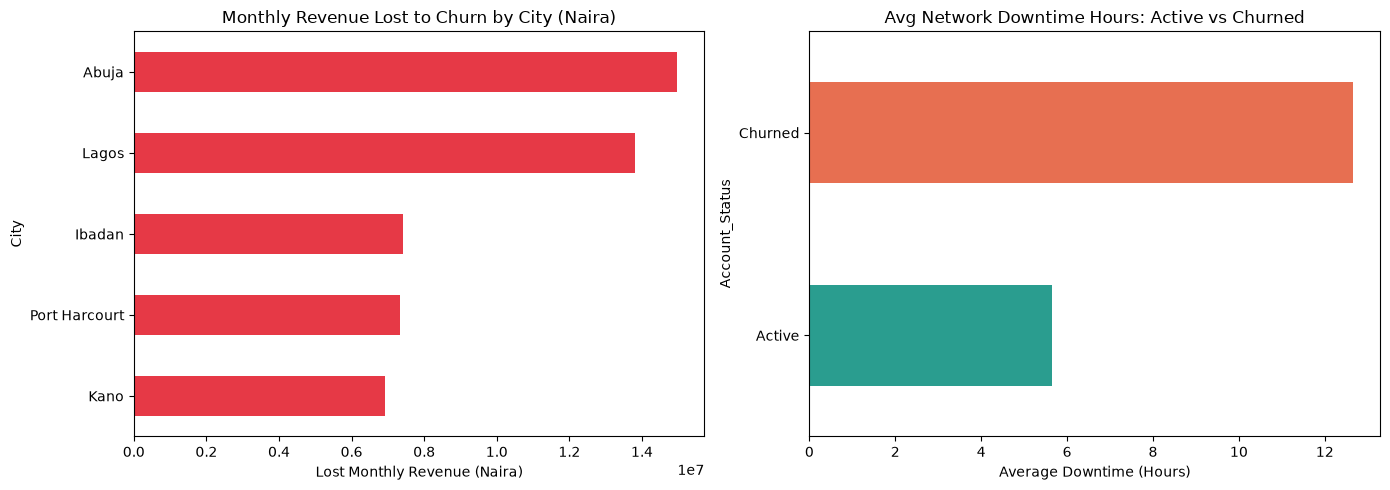

In [5]:
# 1. Calculate Churn Rate % and Revenue Lost by Network Provider across all 15,000 rows
network_summary = df.groupby('Network_Provider').agg(
    Total_Customers=('Customer_ID', 'count'),
    Churned_Customers=('Account_Status', lambda x: (x == 'Churned').sum()),
    Avg_Downtime_Hours=('Network_Downtime_Hours', 'mean'),
    Total_Monthly_Revenue_Naira=('Monthly_Spend_Naira', 'sum')
)
network_summary['Churn_Rate_Percent'] = round((network_summary['Churned_Customers'] / network_summary['Total_Customers']) * 100, 2)
print("--- 15,000 CUSTOMER TELECOM SUMMARY BY NETWORK ---")
display(network_summary.sort_values(by='Total_Customers', ascending=False))

# 2. Compare Churn Rate: Critical Downtime (>12h) vs Normal (<12h)
sla_summary = df.groupby('SLA_Risk_Flag')['Account_Status'].value_counts(normalize=True).unstack() * 100
print("\n--- CHURN RATE % BY NETWORK DOWNTIME SLA ---")
display(round(sla_summary, 2))

# 3. Draw Executive Charts using Matplotlib!
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Chart 1: Churned Revenue by City
churned_df = df[df['Account_Status'] == 'Churned']
churned_df.groupby('City')['Monthly_Spend_Naira'].sum().sort_values().plot(
    kind='barh', ax=axes[0], color='#e63946', title='Monthly Revenue Lost to Churn by City (Naira)'
)
axes[0].set_xlabel('Lost Monthly Revenue (Naira)')

# Chart 2: Average Network Downtime Hours (Active vs Churned)
df.groupby('Account_Status')['Network_Downtime_Hours'].mean().plot(
    kind='barh', ax=axes[1], color=['#2a9d8f', '#e76f51'], title='Avg Network Downtime Hours: Active vs Churned'
)
axes[1].set_xlabel('Average Downtime (Hours)')

plt.tight_layout()
plt.savefig('Telecom_Churn_Python_Charts.png', dpi=300)
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Prepare Features (X) and Target (y: 1 = Churned, 0 = Active)
features = ['Tenure_Months', 'Monthly_Spend_Naira', 'Dropped_Calls_Monthly', 'Network_Downtime_Hours', 'Customer_Support_Calls']
X = df[features]
y = np.where(df['Account_Status'] == 'Churned', 1, 0)

# 2. Split 15,000 rows into 80% Training (12,000 rows) and 20% Testing (3,000 rows)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# 3. Train the Scikit-Learn Random Forest Machine Learning Model
model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
model.fit(X_train, y_train)

# 4. Test the Model's Accuracy on the 3,000 unseen test customers!
predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions) * 100
print(f"🎯 Machine Learning Model Churn Prediction Accuracy: {accuracy:.2f}%\n")

# 5. Show Which Business Factor Drives Churn the Most (Feature Importance)
importance_df = pd.DataFrame({
    'Business_Factor': features,
    'Churn_Impact_Score (%)': np.round(model.feature_importances_ * 100, 2)
}).sort_values(by='Churn_Impact_Score (%)', ascending=False)

print("--- SCIKIT-LEARN FEATURE IMPORTANCE (WHAT DRIVES CHURN?) ---")
display(importance_df)

🎯 Machine Learning Model Churn Prediction Accuracy: 84.60%

--- SCIKIT-LEARN FEATURE IMPORTANCE (WHAT DRIVES CHURN?) ---


,Business_Factor,Churn_Impact_Score (%)
3,Network_Downtime_Hours,66.83
2,Dropped_Calls_Monthly,30.89
0,Tenure_Months,1.24
4,Customer_Support_Calls,0.60
1,Monthly_Spend_Naira,0.43
